# CS5494 Assignment 1

## Environment setup

All shared utilities (data loading, binarization, plotting, timing) live in
`common.py`. Keep `common.py` in the same folder as this notebook.

Dependencies: `torch`, `torchvision`, `numpy<2`, `matplotlib`.

```bash
conda install pytorch torchvision -c pytorch -y
conda install "numpy<2" -y      # torch 2.2.x is built against NumPy 1.x
python check_env.py             # verify, then restart the kernel
```

Why `num_workers=0` below: on macOS, DataLoader worker processes are spawned
and must re-import the main module. A `Binarize` class defined in a notebook
cell lives in `__main__`, which the workers cannot resolve, causing
`AttributeError: Can't get attribute 'Binarize' on <module '__main__'>`.
Moving it into `common.py` plus using `num_workers=0` removes the problem.

In [1]:
import os
# matplotlib needs a writable cache dir; keeps the run clean and quiet
os.environ.setdefault("MPLCONFIGDIR", os.path.join(os.getcwd(), ".mplcache"))
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)

import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from common import (DIM, Timer, get_device, get_loaders, plot_curve, plot_grid,
                    save_samples, to_flat)

# ---- device -----------------------------------------------------------
# NOTE: torch 2.2.x has a known defect in torch.bernoulli on Apple MPS, which
# would corrupt the pixel-by-pixel sampling of every autoregressive model.
# Sample on CPU after training there (see the MPS check at the end).
DEVICE = get_device(prefer="cpu")

torch.manual_seed(0)
np.random.seed(0)

# ---- data -------------------------------------------------------------
# Binarized MNIST, pixels in {0,1}  ->  tasks 1.1 and 1.2
train_loader, test_loader = get_loaders(
    binarize=True, batch_size=128, num_workers=0, tau=0.5)
# Original grayscale MNIST, pixels in [0,1]  ->  task 1.3 (GAN)
raw_loader, _ = get_loaders(binarize=False, batch_size=128, num_workers=0)

x, y = next(iter(train_loader))
print("binarized batch:", tuple(x.shape), "| pixel values:", sorted(set(x.unique().tolist())))
print("labels:", y[:10].tolist())
print("foreground ratio: %.4f (expected ~0.13)" % x.mean().item())

[device] 使用 cpu
binarized batch: (128, 1, 28, 28) | pixel values: [0.0, 1.0]
labels: [6, 8, 8, 7, 8, 0, 0, 5, 6, 0]
foreground ratio: 0.1341 (expected ~0.13)


---
# Task 1.1 — Fully Visible Sigmoid Belief Network (FVSBN)

## Model

The FVSBN factorises the joint distribution of the 784 pixels into a product
of conditionals over a fixed ordering, and models each conditional with a
logistic (sigmoid) unit:

$$p(x) = \prod_{j=1}^{D} p(x_j \mid x_{<j}), \qquad
p(x_j = 1 \mid x_{<j}) = \sigma\!\left(\sum_{i<j} W_{ji} x_i + b_j\right)$$

Two properties make this the simplest member of the family:

* **Fully visible** — the conditionals are conditioned on the observed pixels
  themselves; there is no latent variable and no hidden unit.
* **Autoregressive** — pixel $j$ may depend only on pixels $i < j$. This is
  enforced by a strictly lower-triangular weight mask. A single forward pass
  then yields all 784 conditionals at once, so training is exact maximum
  likelihood (equivalently, the mean binary cross-entropy).

Sampling is **ancestral**: draw $x_1$, feed it back, draw $x_2$, and so on for
784 sequential steps.

Note that because the mask is applied to the input of a linear layer, adding a
hidden layer ($H > 0$) yields a *neural* fully-visible model that is still
strictly autoregressive — that variant is covered in the ablation at the end
of this section.

In [2]:
class FVSBN(nn.Module):
    """Fully Visible Sigmoid Belief Network for 28x28 binary images.

    p(x_j = 1 | x_<j) = sigmoid(W_j . x_<j + b_j)

    H = 0  -> plain logistic regression (one weight per ordered pixel pair),
              which is the FVSBN case named in the assignment.
    H > 0  -> an extra masked hidden layer, still strictly autoregressive.
    """

    def __init__(self, D=DIM, H=0):
        super().__init__()
        self.D, self.H = D, H
        # Strictly lower triangular: row j may see inputs 0..j-1 only.
        self.register_buffer("mask", torch.tril(torch.ones(D, D), diagonal=-1))

        if H == 0:
            self.W = nn.Parameter(torch.zeros(D, D))
            self.b = nn.Parameter(torch.zeros(D))
        else:
            # A dense hidden layer cannot share one (D, D) triangular mask:
            # its shape is (H, D). Instead, following the masked-autoencoder
            # idea (NADE/MADE), each hidden unit k is given its own maximum
            # visible index a_k and may look only at pixels x_i with i < a_k.
            # Hidden unit k then carries information about x_{<a_k} only, so
            # the output mask a_k <= j is exactly what keeps pixel j causal.
            g = torch.Generator().manual_seed(0)
            a = torch.randint(1, D + 1, (H,), generator=g)
            idx = torch.arange(D)
            self.register_buffer("a", a)
            self.register_buffer("maskW1", (idx[None, :] < a[:, None]).float())  # (H, D)
            self.register_buffer("maskW2", (a[None, :] <= idx[:, None]).float()) # (D, H)

            self.W1 = nn.Parameter(torch.randn(H, D, generator=g) * 0.01)
            self.c = nn.Parameter(torch.zeros(H))
            self.W2 = nn.Parameter(torch.randn(D, H, generator=g) * (1.0 / H ** 0.5))
            self.b = nn.Parameter(torch.zeros(D))

    def logits(self, x):
        """x: (B, D) in {0,1}. Returns (B, D) conditional logits."""
        if self.H == 0:
            return F.linear(x, self.W * self.mask, self.b)
        h = torch.sigmoid(F.linear(x, self.W1 * self.maskW1, self.c))
        return F.linear(h, self.W2 * self.maskW2, self.b)

    def loss(self, x):
        """Summed binary cross-entropy over the 784 pixels, in nats.

        This is the negative log-likelihood of the image under the model.
        """
        return F.binary_cross_entropy_with_logits(self.logits(x), x, reduction="sum")

    @torch.no_grad()
    def sample(self, n, device="cpu"):
        """Ancestral sampling: 784 sequential Bernoulli draws."""
        self.eval()
        x = torch.zeros(n, self.D, device=device)
        for j in range(self.D):
            p_j = torch.sigmoid(self.logits(x)[:, j])
            x[:, j] = torch.bernoulli(p_j)
        return x

    def n_params(self):
        return sum(p.numel() for p in self.parameters())


def evaluate_nll(model, loader, device="cpu"):
    """Return (NLL per image in nats, NLL per pixel in nats).

    The per-pixel figure is the interpretable one: it is directly comparable
    to the training curve and to a pixel-independent baseline.
    """
    model.eval()
    total, seen = 0.0, 0
    with torch.no_grad():
        for xb, _ in loader:
            xb = to_flat(xb).to(device)
            total += model.loss(xb).item()
            seen += xb.size(0)
    per_image = total / seen
    return per_image, per_image / DIM


def independent_baseline(loader, device="cpu"):
    """Mean BCE of the best pixel-independent model, i.e. a fixed per-pixel
    probability equal to the empirical pixel frequency.

    This is the natural reference point: whatever the FVSBN gains beyond this
    comes purely from modelling the dependence between pixels.
    """
    n, s = 0, None
    with torch.no_grad():
        for xb, _ in loader:
            xb = to_flat(xb).to(device)
            s = xb.sum(0) if s is None else s + xb.sum(0)
            n += xb.size(0)
    p = (s / n).clamp(1e-6, 1 - 1e-6)          # (D,) empirical frequency
    bce = -(p * p.log() + (1 - p) * (1 - p).log()).mean()
    return bce.item()


def train_fvsbn(model, loader, epochs=30, lr=1e-3, device="cpu",
                sample_at=(), n_sample=4, verbose=True):
    """Train by maximum likelihood; snapshot samples at chosen epochs.

    Returns (history, stages). history holds the mean loss per epoch and per
    pixel (a per-batch value would give a jagged, unusable curve).
    """
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n_images = len(loader.dataset)
    history = {"train_nll_per_pixel": []}
    stages = []

    for ep in range(1, epochs + 1):
        model.train()
        total, seen = 0.0, 0
        for xb, _ in loader:
            xb = to_flat(xb).to(device)
            loss = model.loss(xb) / xb.size(0)      # per-image NLL
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * xb.size(0)
            seen += xb.size(0)
        mean_nll = total / seen
        history["train_nll_per_pixel"].append(mean_nll / DIM)

        if ep in sample_at:
            stages.append(model.sample(n_sample, device=device).cpu())
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"epoch {ep:3d}/{epochs}  train NLL/pixel = "
                  f"{mean_nll / DIM:.4f} nats")

    return history, stages


# ---- train ------------------------------------------------------------
EPOCHS = 30
SAMPLE_AT = (1, 8, 16, 23, 30)          # 5 stages -> the required 5x4 grid
model = FVSBN(D=DIM, H=0)               # H=0: plain logistic regression

timer = Timer()
timer.start()
history, stages = train_fvsbn(model, train_loader, epochs=EPOCHS, lr=1e-3,
                              device=DEVICE, sample_at=SAMPLE_AT, n_sample=4)
train_time = timer.stop("train_total")

nll_img, nll_px = evaluate_nll(model, test_loader, DEVICE)
baseline_px = independent_baseline(train_loader, DEVICE)

print()
print(f"parameters    : {model.n_params():,}")
print(f"training time : {train_time:.1f} s")
print()
print(f"test NLL      : {nll_img:8.2f} nats/image   ({nll_px:.4f} nats/pixel)")
print(f"pixel-independent baseline :        ({baseline_px:.4f} nats/pixel)")
print(f"gain over the baseline     :        "
      f"({baseline_px - nll_px:.4f} nats/pixel)")

epoch   1/30  train NLL/pixel = 0.3371 nats


epoch   5/30  train NLL/pixel = 0.1572 nats


epoch  10/30  train NLL/pixel = 0.1162 nats


epoch  15/30  train NLL/pixel = 0.1038 nats


epoch  20/30  train NLL/pixel = 0.0993 nats


epoch  25/30  train NLL/pixel = 0.0973 nats


epoch  30/30  train NLL/pixel = 0.0964 nats



parameters    : 615,440
training time : 71.0 s

test NLL      :    76.19 nats/image   (0.0972 nats/pixel)
pixel-independent baseline :        (0.2628 nats/pixel)
gain over the baseline     :        (0.1656 nats/pixel)


[plot_curve] 已保存 results/task1_loss_curve.png


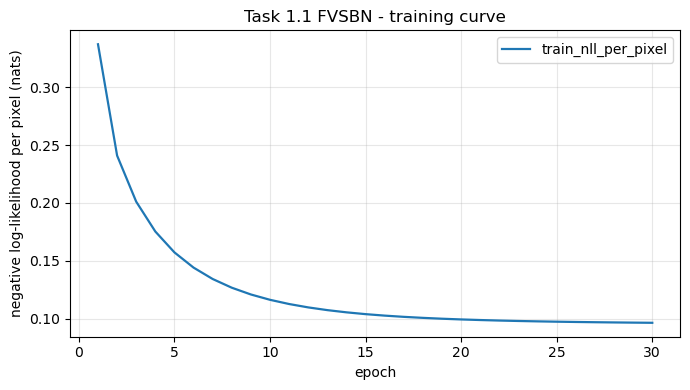

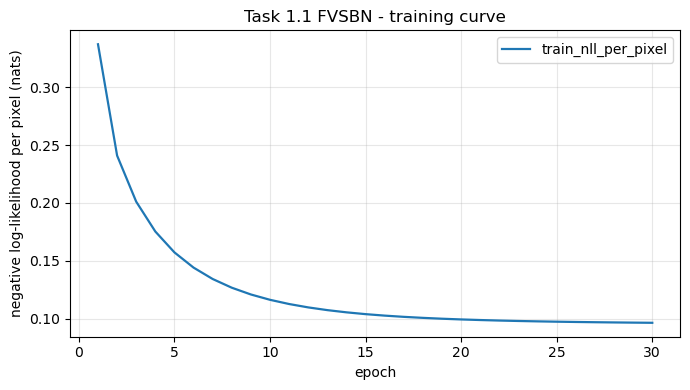

In [3]:
# ---- training curve ---------------------------------------------------
plot_curve(history, keys=["train_nll_per_pixel"],
           title="Task 1.1 FVSBN - training curve",
           ylabel="negative log-likelihood per pixel (nats)",
           savepath="results/task1_loss_curve.png")

[plot_grid] 已保存 results/task1_progress_grid.png


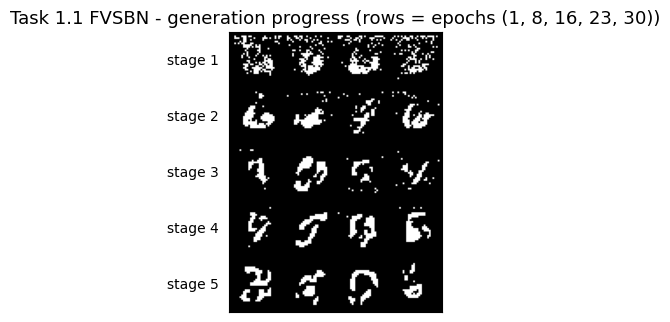

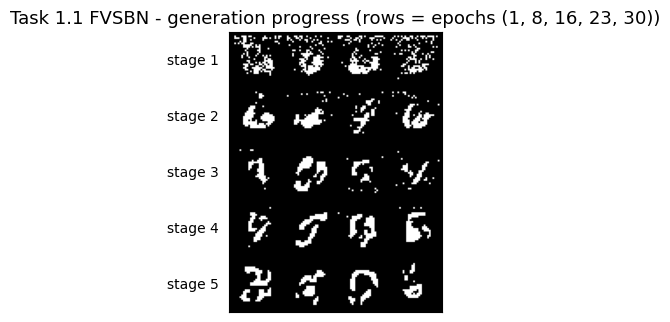

In [4]:
# ---- training progress: 5 rows x 4 columns ----------------------------
# Each row is one training stage; quality should improve top to bottom.
plot_grid(stages, nrow=4,
          title="Task 1.1 FVSBN - generation progress (rows = epochs %s)" % (SAMPLE_AT,),
          savepath="results/task1_progress_grid.png")

[plot_grid] 已保存 results/task1_samples.png


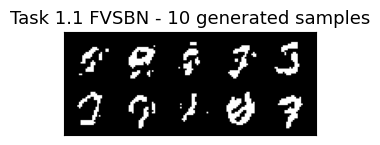

[save_samples] 已保存 results/task1_samples.npy  形状=(10, 784)
sampling 10 images: 0.26 s total (0.0256 s per image)


In [5]:
# ---- final samples ----------------------------------------------------
# At least 10 generated images, as recommended by the assignment.
N_GEN = 10
t = Timer(); t.start()
samples = model.sample(N_GEN, device=DEVICE).cpu()
infer_time = t.stop("sample_%d" % N_GEN)

plot_grid(samples, nrow=5,
          title="Task 1.1 FVSBN - %d generated samples" % N_GEN,
          savepath="results/task1_samples.png")
save_samples(samples, "results/task1_samples.npy")
print("sampling %d images: %.2f s total (%.4f s per image)" % (N_GEN, infer_time, infer_time / N_GEN))

In [6]:
# ---- quantitative evaluation -----------------------------------------
# The NLL of the FVSBN is exact and closed-form (no bound, no approximation),
# so it can be reported directly.
nll_img, nll_px = evaluate_nll(model, test_loader, DEVICE)
print(f"test  NLL : {nll_img:8.2f} nats/image  ({nll_px:.4f} nats/pixel, "
      f"{nll_px / np.log(2):.4f} bits/pixel)")
print(f"train NLL : {history['train_nll_per_pixel'][-1] * DIM:8.2f} nats/image  "
      f"({history['train_nll_per_pixel'][-1]:.4f} nats/pixel)")
print(f"pixel-independent baseline : {baseline_px:.4f} nats/pixel")
print(f"gain over that baseline    : {baseline_px - nll_px:+.4f} nats/pixel")

# Ground-truth foreground rate vs. what the model generates
gen = model.sample(500, device=DEVICE)
print(f"\nforeground ratio  real data {x.mean().item():.4f}  generated {gen.mean().item():.4f}")

test  NLL :    76.19 nats/image  (0.0972 nats/pixel, 0.1402 bits/pixel)
train NLL :    75.55 nats/image  (0.0964 nats/pixel)
pixel-independent baseline : 0.2628 nats/pixel
gain over that baseline    : +0.1656 nats/pixel



foreground ratio  real data 0.1341  generated 0.1355


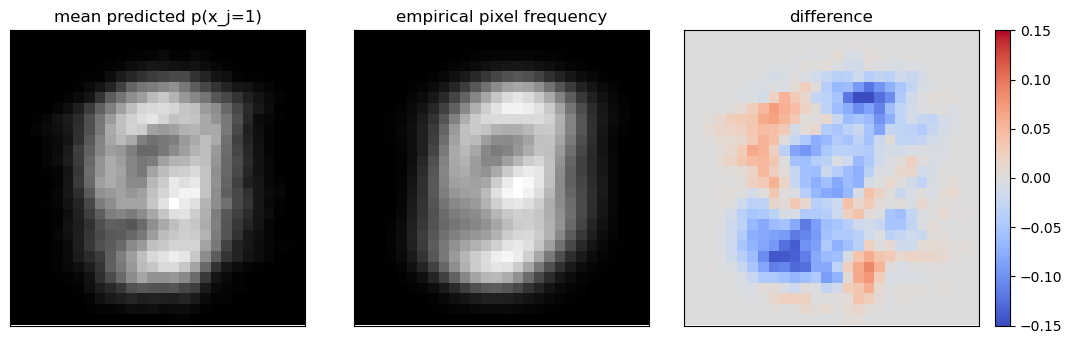

mean absolute error: 0.0200


In [7]:
# ---- per-pixel fit ---------------------------------------------------
# A useful diagnostic: compare the model's average predicted probability with
# the empirical pixel frequency of the data.
model.eval()
with torch.no_grad():
    xb, _ = next(iter(test_loader))
    xb = to_flat(xb).to(DEVICE)
    pred = torch.sigmoid(model.logits(xb)).mean(0).cpu().numpy()

# Empirical frequency over the whole test set
s, n = None, 0
with torch.no_grad():
    for xb2, _ in test_loader:
        xb2 = to_flat(xb2).to(DEVICE)
        s = xb2.sum(0) if s is None else s + xb2.sum(0)
        n += xb2.size(0)
emp = (s / n).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].imshow(pred.reshape(28, 28), cmap="gray"); axes[0].set_title("mean predicted p(x_j=1)")
axes[1].imshow(emp.reshape(28, 28), cmap="gray");  axes[1].set_title("empirical pixel frequency")
im = axes[2].imshow((pred - emp).reshape(28, 28), cmap="coolwarm",
                    vmin=-0.15, vmax=0.15)
axes[2].set_title("difference"); plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig("results/task1_pixel_fit.png", dpi=150, bbox_inches="tight")
plt.show()
print("mean absolute error: %.4f" % np.abs(pred - emp).mean())

In [8]:
# ---- causality check -------------------------------------------------
# The autoregressive property is the one thing that is easy to get silently
# wrong. Verify it numerically: the logit of pixel j must not depend on any
# pixel i >= j. We perturb the future pixels and confirm the earlier logits
# are unchanged.
model.eval()
xb, _ = next(iter(test_loader))
xb = to_flat(xb)[:4].to(DEVICE)

with torch.no_grad():
    base = model.logits(xb)

worst = 0.0
for j in range(1, DIM, 37):                     # sample a few pivot pixels
    xp = xb.clone()
    xp[:, j:] = 1.0 - xp[:, j:]                 # flip all pixels from j onward
    with torch.no_grad():
        changed = (model.logits(xp)[:, :j] - base[:, :j]).abs().max().item()
    worst = max(worst, changed)

print(f"max change in logits of pixels < j when flipping all pixels >= j: {worst:.3e}")
print("OK - strictly autoregressive" if worst < 1e-4 else "LEAKAGE DETECTED")
assert worst < 1e-4, "information leakage from future pixels"

max change in logits of pixels < j when flipping all pixels >= j: 0.000e+00
OK - strictly autoregressive


### Ablation — capacity of the conditional model

The assignment asks for hyper-parameter analysis and ablation studies, so the
baseline is rerun with a masked hidden layer of increasing width. `H = 0` is
the plain logistic-regression FVSBN required in item 1.1; `H > 0` keeps the
model strictly autoregressive while letting it share statistical strength
across pixels.

Reported numbers to compare: trainable parameters, test NLL per image, and
training time.

In [9]:
# ---- ablation over hidden width --------------------------------------
ablation = []
run_cfg = [dict(H=0, epochs=30), dict(H=64, epochs=30),
           dict(H=256, epochs=30), dict(H=512, epochs=30)]

for cfg in run_cfg:
    torch.manual_seed(0)
    m = FVSBN(D=DIM, H=cfg["H"])
    tt = Timer(); tt.start()
    hist, _ = train_fvsbn(m, train_loader, epochs=cfg["epochs"], lr=1e-3,
                          device=DEVICE, verbose=False)
    secs = tt.stop("t")
    img_nll, px_nll = evaluate_nll(m, test_loader, DEVICE)
    ablation.append(dict(H=cfg["H"], params=m.n_params(),
                         test_nll=img_nll, test_nll_px=px_nll, seconds=secs))
    print(f"H={cfg['H']:4d}  params={m.n_params():>9,}  "
          f"test NLL={px_nll:.4f} nats/pixel  ({secs:6.1f}s)")

H=   0  params=  615,440  test NLL=0.0972 nats/pixel  (  75.9s)


H=  64  params=  101,200  test NLL=0.1661 nats/pixel  (  63.4s)


H= 256  params=  402,448  test NLL=0.1189 nats/pixel  (  75.8s)


H= 512  params=  804,112  test NLL=0.1043 nats/pixel  (  86.1s)


In [10]:
# ---- ablation table ---------------------------------------------------
print(f"pixel-independent baseline: {baseline_px:.4f} nats/pixel")
print()
print(f"{'H':>6} {'params':>12} {'NLL nats/px':>13} {'NLL bits/px':>13} "
      f"{'NLL nats/img':>14} {'time (s)':>10}")
print("-" * 74)
for r in ablation:
    print(f"{r['H']:>6} {r['params']:>12,} {r['test_nll_px']:>13.4f} "
          f"{r['test_nll_px'] / np.log(2):>13.4f} {r['test_nll']:>14.1f} "
          f"{r['seconds']:>10.1f}")

pixel-independent baseline: 0.2628 nats/pixel

     H       params   NLL nats/px   NLL bits/px   NLL nats/img   time (s)
--------------------------------------------------------------------------
     0      615,440        0.0972        0.1403           76.2       75.9
    64      101,200        0.1661        0.2396          130.2       63.4
   256      402,448        0.1189        0.1715           93.2       75.8
   512      804,112        0.1043        0.1505           81.8       86.1


In [11]:
# ---- why sampling runs on CPU: MPS Bernoulli check -------------------
# torch 2.2.x has a known defect in torch.bernoulli on Apple MPS. This checks
# it on this machine; if it fails, keep DEVICE = "cpu" for sampling.
if torch.backends.mps.is_available():
    try:
        p = torch.full((1000,), 0.5, device="mps")
        s = torch.bernoulli(p)
        ok = bool(torch.isfinite(s).all()) and 0.4 < s.mean().item() < 0.6
        print("MPS torch.bernoulli:", "OK" if ok else "BROKEN (keep CPU sampling)",
              "| mean =", round(s.mean().item(), 4))
    except Exception as e:
        print("MPS torch.bernoulli unavailable:", type(e).__name__, "-> keep CPU sampling")
else:
    print("no MPS on this machine")

print()
print(timer.summary())
print(f"sampling {N_GEN} images: {infer_time:.2f} s")

MPS torch.bernoulli: OK | mean = 0.488

计时结果：
  train_total :    71.00 秒  (1.18 分钟)
sampling 10 images: 0.26 s
